<a href="https://colab.research.google.com/github/edsonportosilva/OpticalCommunications/blob/main/jupyter%20notebooks/English/2.%20Optical%20receivers%20and%20noise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
if 'google.colab' in str(get_ipython()):    
    ! git clone -b main https://github.com/edsonportosilva/OptiCommPy
    from os import chdir as cd
    cd('/content/OptiCommPy/')
    ! pip install .
    cd('/content/')
    ! wget https://raw.githubusercontent.com/edsonportosilva/OpticalCommunications/main/jupyter%20notebooks/English/utils.py

In [2]:
from optic.utils import parameters
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
from numpy.random import normal
from scipy import constants
from optic.comm.metrics import signalPower
from optic.dsp.core import firFilter, pulseShape, lowPassFIR, upsample
from optic.models.devices import mzm, photodiode
from optic.plot import eyediagram
from optic.utils import parameters
from numpy.fft import fft, ifft, fftshift, fftfreq

In [3]:
from IPython.core.display import HTML
from IPython.core.pylabtools import figsize
from IPython.display import display, Math

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

In [4]:
figsize(10, 3)

In [5]:
%load_ext autoreload
%autoreload 2

# Optical Communications

# Optical receivers and noise

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Receivers-for-optical-communications-systems" data-toc-modified-id="Receivers-for-optical-communications-systems-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Receivers for communications systems optical</a></span><ul class="toc-item"><li><span><a href="#Function-of-an-optical-receiver" data-toc-modified-id="Function-of-an-optical-receiver-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>Function of a receiver optical</a></span></li><li><span><a href="#Receivers-for-intensity-modulation-and-direct-detection-systems" data-toc-modified-id="Receivers-for-intensity-modulation-and-direct-detection-systems-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>Receivers for intensity modulation and direct detection systems</a></span></li></ul></li><li><span><a href="#Sources-of-noise-in-optical-detectors" data-toc-modified-id="Sources-of-noise-in-optical-detectors-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Sources of noise in optical detectors</a></span><ul class="toc-item"><li><span><a href="#Shot-noise-(or-ballistic-noise)" data-toc-modified-id="Shot-noise-(or-ballistic-noise)-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Gunshot noise (or ballistic noise)</a></span></li><li><span><a href="#Gunshot-noise-power" data-toc-modified-id="Gunshot-noise-power-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>Shot noise power</a></span><ul class="toc-item"><li><span><a href="#Calculating-the-power-of-a-signal" data-toc-modified-id="Calculating-the-power-of-a-signal-2.2.1"><span class="toc-item-num">2.2.1&nbsp;&nbsp;</span>Calculating the power of a signal</a></span></li></ul></li><li><span><a href="#Thermal-noise" data-toc-modified-id="Thermal-noise-2.3"><span class="toc-item-num">2.3&nbsp;&nbsp;</span>Thermal Noise</a></span></li><li><span><a href="#Thermal-Noise-Power" data-toc-modified-id="Thermal-Noise-Power-2.4"><span class="toc-item-num">2.4&nbsp;&nbsp;</span>Thermal Noise Ratio</a></span></li><li><span><a href="#signal-to-noise-ratio---SNR)" data-toc-modified-id="signal-to-noise-ratio---SNR)-2.5"><span class="toc-item-num">2.5&nbsp;&nbsp;</span>Signal-to-noise ratio (<em>signal-to-noise ratio</em> - SNR)</a></span></li><li><span><a href="#p-i-n-receptors" data-toc-modified-id="p-i-n-receptors-2.6"><span class="toc-item-num">2.6&nbsp;&nbsp;</span>p-i-n receptors</a></span><ul class="toc-item"><li><span><a href="#Thermal-Noise-Limit-$(\sigma_{T}^{2}-\gg-\sigma_{s}^{2})$" data-toc-modified-id="Thermal-Noise-Limit-$(\sigma_{T}^{2}-\gg-\sigma_{s}^{2})$-2.6.1"><span class="toc-item-num">2.6.1&nbsp;&nbsp;</span>Thermal noise threshold $(\sigma_{T}^{2} \gg \sigma_{s}^{2})$</a></span></li><li><span><a href="#Shot-noise-threshold-$(\sigma_{s}^{2}-\gg-\sigma_{T}^{2})$" data-toc-modified-id="Shot-noise-threshold-$(\sigma_{s}^{2}-\gg-\sigma_{T}^{2})$-2.6.2"><span class="toc-item-num">2.6.2&nbsp;&nbsp;</span>Shot noise threshold $(\sigma_{s}^{2} \gg \sigma_{T}^{2})$</a></span></li><li><span><a href="#Typical-Parameters" data-toc-modified-id="Typical-Parameters-2.6.3"><span class="toc-item-num">2.6.3&nbsp;&nbsp;</span>Typical Parameters</a></span></li></ul></li><li><span><a href="#Simulating-the-transmitter-10G-OOK" data-toc-modified-id="Simulating-the-10G-OOK-transmitter-2.7"><span class="toc-item-num">2.7&nbsp;&nbsp;</span>Simulating the 10G OOK transmitter</a></span></li><li><span><a href="#Simulating-the-noise-sources-of-the-receiver-p-i-n" data-toc-modified-id="Simulating-the-noise-sources-of-the-p-i-n-receiver-2.8"><span class="toc-item-num">2.8&nbsp;&nbsp;</span>Simulating the noise sources of the p-i-n receiver</a></span></li><li><span><a href="#APD-based-receivers" data-toc-modified-id="APD-based-receivers-2.9"><span class="toc-item-num">2.9&nbsp;&nbsp;</span>APD-based receivers</a></span><ul class="toc-item"><li><span><a href="#Shot-Noise" data-toc-modified-id="Shot-Noise-2.9.1"><span class="toc-item-num">2.9.1&nbsp;&nbsp;</span>Shot Noise firing</a></span></li></ul></li></ul></li><li><span><a href="#Receptor-Sensitivity" data-toc-modified-id="Receptor-Sensitivity-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Receptor Sensitivity</a></span><ul class="toc-item"><li><span><a href="#Canal-AWGN-(Additive-White-Gaussian-Noise-Channel)" data-toc-modified-id="Canal-AWGN-(Additive-White-Gaussian-Noise-Channel)-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>AWGN Channel (<em>Additive White Gaussian Noise Channel</em>)</a></span></li><li><span><a href="#Filtering-on-receiver" data-toc-modified-id="Filtering-on-receiver-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Filtering on the receiver</a></span></li><li><span><a href="#Married-Filter" data-toc-modified-id="Married-Filter-3.3"><span class="toc-item-num">3.3&nbsp;&nbsp;</span>Married-Filter</a></span></li><li><span><a href="#Optimal-decisionmaker:-evaluating-probabilities" data-toc-modified-id="Optimal-decision-maker: evaluating-probabilities-3.4"><span class="toc-item-num">3.4&nbsp;&nbsp;</span>Optimal-decision-maker: evaluating probabilities</a></span><ul class="toc-item"><li><span><a href="#Metric-of-probabilities-a-posteriori-(MP)" data-toc-modified-id="Metrica-de-probabilities-a-posteriori-(MP)-3.4.1"><span class="toc-item-num">3.4.1&nbsp;&nbsp;</span>Metric of <em>probabilities a posteriori</em> (MP)</a></span></li><li><span><a href="#Optimal-Decision-Threshold-$I_d$" data-toc-modified-id="Optimal-Decision-Threshold-$I_d$-3.4.2"><span class="toc-item-num">3.4.2&nbsp;&nbsp;</span>Optimal Decision Threshold $I_d$</a></span></li></ul></li><li><span><a href="#Probability-of-bit-error-$P_b$" data-toc-modified-id="Probability-of-bit-error-$P_b$-3.5"><span class="toc-item-num">3.5&nbsp;&nbsp;</span>Probability of bit error $P_b$</a></span><ul class="toc-item"><li><span><a href="#Example:-simulation-10G-OOK" data-toc-modified-id="Example:-simulation-10G-OOK-3.5.1"><span class="toc-item-num">3.5.1&nbsp;&nbsp;</span>Example: 10G simulation OOK</a></span></li></ul></li></ul></li></ul></div>

## Receivers for optical communications systems

### Function of an optical receiver
<img src="../figuras/Rx_OOK.png" width="400">

### Receivers for intensity modulation and direct detection systems
<img src="../figuras/Rx_IMDD.png" width="800">

## Sources of noise in optical detectors

Noise is random and undesirable distortions that affect signals that carry information, making the communication process difficult or impossible. In order to analyze the performance of a given communications system, it is necessary that all noise sources present in it are characterized. In the case of receivers in optical communications systems, two sources of noise are important: shot noise generated in the photodetection process and thermal noise from electronic components.

### Shot noise (or ballistic noise)

The current $I(t)$ generated by the conversion of the optical signal power incident on the photodiode can be written as

$$
\begin{equation}\label{eq1}
I(t)=I_{p}(t) + i_{s}(t)
\end{equation}
$$

where $i_{s}(t)$ represents a random process known as shot noise and $I_{p}(t)$ corresponds to the current proportional to the responsiveness and optical power incident on the photodiode, given by

$$
\begin{equation}\label{eq2}
I_{p}(t)=R_{d} P_{\text {in}}(t).
\end{equation}
$$

The shot noise $i_{s}(t)$ is well characterized as a stationary random process with a Poisson statistic that, in general, is approximated by a Gaussian statistic, which facilitates its mathematical treatment.

Let $R_{i_s}(\tau)$ be the autocorrelation function of $i_s(t)$ will be given by

$$
\begin{equation} \label{eq3}
R_{i_s}(\tau) = E\left[i_s(t)i_s(t+\tau)\right].
\end{equation}
$$

By the Wiener-Kinchin theorem, the spectral density and power $S_{i_s}(f)$ associated with $i_s(t)$ is given by the Fourier transform of $R_{i_s}(\tau)$, so that 

$$
\begin{align}
S_{i_s}(f) &= \int_{-\infty}^{\infty}R_{i_s}(\tau)e^{-j2\pi f \tau} d\tau\nonumber \\
R_{i_s}(\tau) &= \int_{-\infty}^{\infty}S_{i_s}(f)e^{j2\pi f \tau} df\label{eq4}
\end{align}
$$

In the case of shot noise, the power spectral density is constant and given by $S_{i_s}(f)=q\bar{I}_p$, where 
$\bar{I}_p$ is the average value of the photocurrent, defined by

$$
\begin{equation}\label{eq5}
\bar{I}_p = \frac{1}{T_s} \int_{-T_s/2}^{T_s/2}E[I_p(t)]dt.
\end{equation}
$$

where $T_s$ is the transmission signaling period.

### Shot noise strength

The power of the shot noise will correspond to its variance $\sigma_{s}^{2}$. Let $B$ be the band of the optical receiver in $\mathrm{Hz}$, $\sigma_{s}^{2}$ can be calculated by

$$
\begin{align}
\sigma_{s}^{2} &= E\left[i_{s}^{2}(t)\right] = R_{i_s}(0) \nonumber\\
               &= \int_{-\infty}^{\infty} S_{i_s}(f) df = \int_{-B}^{B} S_{i_s}(f) df \nonumber \\
               &= 2 q \bar{I}_{p} B \label{eq6}
\end{align}
$$

Since the photodiode dark current $I_d$ (*dark current*) also contributes to the shot noise, it must be included in (\ref{eq6}), so that the final expression for the shot noise variance will be given by

$$
\begin{equation}\label{eq7}
\sigma_{s}^{2} = 2 q (\bar{I}_{p} + I_d) B.
\end{equation}
$$

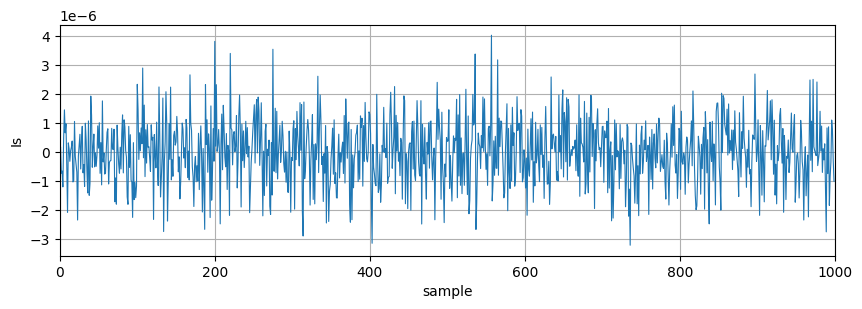

In [6]:
Pin_dBm = -1   # average optical power in dBm: Khai báo công suất quang trung bình đi vào bộ thu theo đơn vị logarithmic
Rd  = 0.5      # A/W responsiveness: Độ nhạy quang (Responsivity R) của Photodiode tức mỗi 1 cs quang tạo ra 0.5A dòng điện.
Id  = 100e-9   # dark current in nA: Khai báo dòng điện tối trong photodiode
B   = 10e9     # receiver band in Hz: Khai báo băng tần của bộ thu (băng thông điện tử, băng thông mạng, băng thông kts)

q  = constants.value('elementary charge') # elementary charge of the electron q=1.6x10^-19 C

Pin = 10**(Pin_dBm/10)*1e-3 # average optical power in W -1dbm = 0.794 mW
Ip  = Rd*Pin #Tính dòng quang điện trung bình Ip = 0.397mA

# shot noise (white Gaussian noise)
Namostras = 100000 #tổng số lượng mẫu mô phỏng

σ2_s = 2*q*(Ip + Id)*B  # variance: tính phương sai nhiễu hạt theo công thức lý thuyết 
μ    = 0                # average: Đặt giá trị kỳ vọng (trung bình) của dòng nhiễu bằng 0A (vì phần trung bình DC đã nằm ở Ip)

σ     = np.sqrt(σ2_s) #Tính độ lệch chuẩn (biên độ hiệu dụng RMS của dòng nhiễu).
Is    = normal(μ, σ, Namostras) #Tạo chuỗi ngẫu nhiên Is(t) gồm 100000 mẫu tuân theo phân bố chuẩn (Gauss) có trung bình u = 0 và độ lệch chuẩn sigma.

# plots the first 1000 samples
plt.plot(Is[0:1000],linewidth = 0.8); #Vẽ đồ thị dạng sóng nhiễu hạt của 1000 mẫu đầu tiên với độ dày nét vẽ 0.8.
plt.xlim(0,1000) #trục X từ mẫu 0 đến mẫu 1000.
plt.ylabel('Is') #trục Y là dòng nhiễu hạt Is(t) theo đơn vị Ampe (A).
plt.xlabel('sample') #trục X là số thứ tự mẫu (sample) từ 0 đến 1000.
plt.grid() # Hiển thị lưới trên đồ thị.

In [7]:
# pdf of a Gaussian random variable with mean μ and standard deviation σ
#Định nghĩa hàm PDF Gauss
def gaussian(x, μ, σ):
    return np.exp(-((x - μ)**2)/(2*σ**2))/np.sqrt(2*np.pi*σ**2)

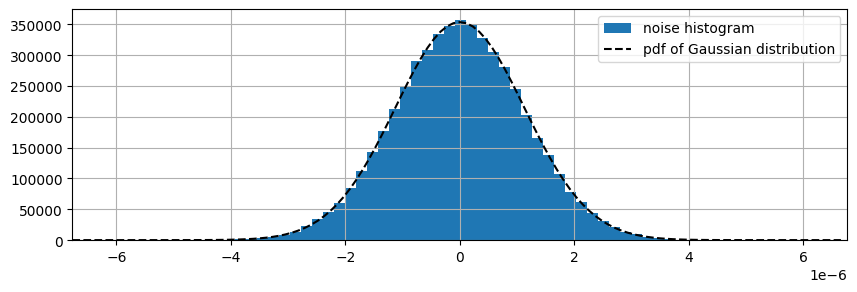

In [8]:
#Vẽ Biểu đồ tần suất nhiễu (Noise Histogram) và Đường pdf của pbo gauss
plt.hist(Is,51, density=True, label = 'noise histogram');
   #Vẽ biểu đồ cột (histogram) phân bố thực tế từ mảng 100,000 mẫu nhiễu Is
   #sau đó Chia toàn bộ dải giá trị nhiễu thành 51 khoảng (bins).
   #density=True: Chuẩn hóa diện tích các cột về tổng bằng 1 để so sánh trực tiếp với hàm mật độ xác suất (PDF).
plt.grid()

x   = np.arange(-6*σ,6*σ, σ/10) # Tạo mảng x từ -6σ đến +6σ với bước nhảy bằng σ/10 để vẽ đường PDF.
fdp = gaussian(x,μ,σ) #Tính giá trị hàm mật độ xác suất (PDF) của phân bố Gauss tại các điểm x với trung bình μ và độ lệch chuẩn σ.

plt.plot(x,fdp,'k--',label ='pdf of Gaussian distribution'); 
plt.legend(); 
plt.xlim(-6*σ,6*σ); # Giới hạn trục X từ -6σ đến +6σ để hiển thị đầy đủ phân bố Gauss.

<IPython.core.display.Math object>

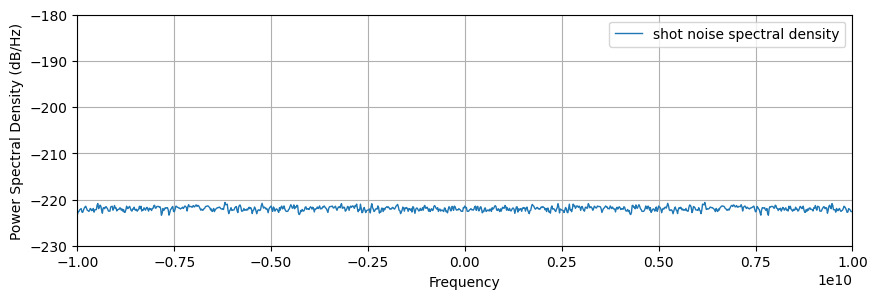

In [9]:
fa = 20e9 # sampling frequency considered: Khai báo tần số lấy mẫu fa = 20GHz để tính toán mật độ phổ công suất (PSD) của nhiễu hạt.

plt.figure()
plt.xlim(-fa/2, fa/2) # Giới hạn trục X từ -fa/2 đến +fa/2 để hiển thị phổ nhiễu hạt trong khoảng tần số từ -10GHz đến +10GHz.
plt.ylim(-230, -180) # Giới hạn trục Y từ -230 dBW/Hz đến -180 dBW/Hz để hiển thị mật độ phổ công suất (PSD) của nhiễu hạt.
plt.psd(Is, Fs=fa, label='shot noise spectral density',\
                   linewidth=1,  sides='twosided' , NFFT=1024); # estimates signal power spectral density
  #Hàm ước lượng Mật độ phổ công suất (Power Spectral Density) từ mảng dữ liệu Is
plt.legend()

display(Math('S_{i_s}(f) = %.2f \\;\\mathrm{dBW/Hz}'%(10*np.log10(σ2_s/(2*B)))))

#### Calculating the power of a signal

$$\begin{equation}\label{eq8}
P_x = E\left[X^2\right] = \mu^2 + \sigma^2\approx \frac{1}{N}\sum_{k=1}^{N} x^2[k]
\end{equation}
$$

In [10]:
Pn = signalPower(Is) 
# Tính công suất nhiễu Pn bằng cách sử dụng hàm signalPower() từ thư viện optic.comm.metrics, hàm này tính toán công suất trung bình của tín hiệu nhiễu Is(t) dựa trên các mẫu dữ liệu.
# Pn= 1.27 pW
print('Noise power (in W) = %.2e W' %Pn) # Tính công suất nhiễu trong đơn vị W (Watt) và in ra màn hình 
print('Noise power (in dBm) = %.2f dBm' %(10*np.log10(Pn/1e-3))) # Tính công suất nhiễu trong đơn vị dBm

Noise power (in W) = 1.28e-12 W
Noise power (in dBm) = -88.94 dBm


### Thermal noise

Thermal noise originates from the thermal agitation of electrons present in the material that constitutes a given electronic device subjected to a given temperature. In this way, the electronic circuits that make up the *front-end* of receivers in communication systems naturally add thermal noise to the detected signals. Therefore, in an optical receiver, the microelectronic circuits responsible for processing the electrical signal obtained in the photodetection process will also be sources of thermal noise.

Like shot noise, thermal noise has additive characteristics and can be modeled by a stationary Gaussian random process. Therefore, we can rewrite the equation (\ref{eq1}) by adding the thermal noise component $i_{T}(t)$, so that

$$
\begin{equation}\label{eq9}
I(t)=I_{p}+i_{s}(t)+i_{T}(t)
\end{equation}
$$

The power spectral density $S_{T}(f)$ of thermal noise is constant and independent of frequency up to $\sim 1 \mathrm{THz}$ and given by

$$
\begin{equation}\label{eq10}
S_{T}(f) =2 k_{B} T/R_{L}
\end{equation}
$$

where $k_B$ is the Boltzmann constant, $T$ is the temperature on the Kelvin scale and $R_L$ is the load resistor.

### Thermal noise power

Again making use of the properties of power spectral density, we have

$$
\begin{align}
\sigma_{T}^{2} &=E\left[ i_{T}^{2}(t)\right]\nonumber\\
               &=\int_{-\infty}^{\infty} S_{T}(f) df\nonumber\\
               &=\int_{-B}^{B} S_{T}(f) df\nonumber\\
               &=\left(4 k_{B} T / R_{L}\right) B\label{eq11}
\end{align}
$$

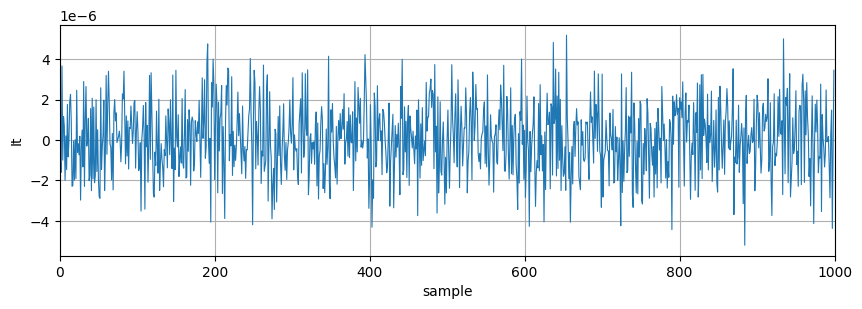

In [11]:
Tc = 25           # temperature in Celsius: Khai báo nhiệt độ môi trường hoạt động của bộ thu quang là 25 độ C (Celsius). Nhiệt độ này sẽ được sử dụng để tính toán nhiễu nhiệt (thermal noise) trong mạch điện tử của bộ thu quang.
B  = 10e9         # receiver band: Khai báo băng tần của bộ thu (băng thông điện tử, băng thông mạng, băng thông kts)
RL = 50           # RL to Ohms: Khai báo điện trở tải (load resistor) của bộ thu quang là 50 Ohms, đây là giá trị tiêu chuẩn trong các hệ thống truyền thông quang.

T = Tc + 273.15   # temperature in Kelvin: Chuyển đổi nhiệt độ từ độ C sang Kelvin bằng cách cộng thêm 273.15.
# T = 25 + 273.15 = 298.15K

kB  = constants.value('Boltzmann constant') # Boltzmann constant in J/K

# thermal noise (white Gaussian noise)
Namostras = 100000 #Khởi tạo 100,000 mẫu mô phỏng để đảm bảo độ tin cậy về mặt thống kê.

σ2_T = 4*kB*T*B/RL  # variance: Tính toán phương sai nhiễu nhiệt
μ    = 0            # average: Đặt giá trị kỳ vọng (trung bình) của dòng nhiễu bằng 0A (vì phần trung bình DC đã nằm ở Ip)

σ     = np.sqrt(σ2_T) # Tính độ lệch chuẩn (biên độ hiệu dụng RMS của dòng nhiễu).
It    = normal(μ, σ, Namostras)  # Tạo chuỗi ngẫu nhiên It(t) gồm 100000 mẫu tuân theo phân bố chuẩn (Gauss) có trung bình u = 0 và độ lệch chuẩn sigma.

# plots the first 1000 samples
plt.plot(It[0:1000],linewidth = 0.8);
plt.xlim(0,1000)
plt.ylabel('It')
plt.xlabel('sample')
plt.grid()

<IPython.core.display.Math object>

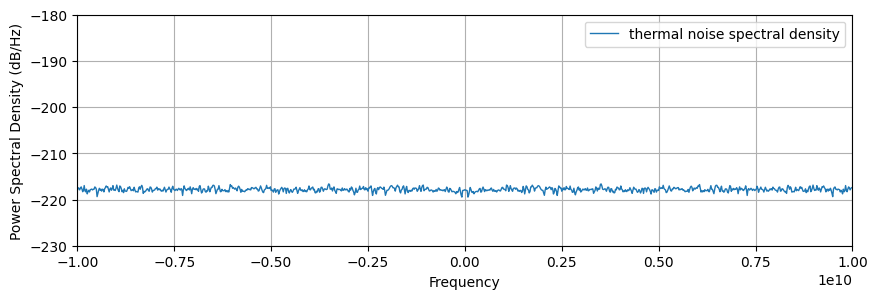

In [12]:
fa = 20e9   # sampling frequency considered

plt.figure()
plt.xlim(-fa/2, fa/2)
plt.ylim(-230, -180)
plt.psd(It, Fs=fa, label='thermal noise spectral density',linewidth=1,  sides='twosided', NFFT=1024); # estimates spectral density of the signal
plt.legend()

display(Math('S_{i_T}(f) = %.2f \\;\\mathrm{dBW/Hz}'%(10*np.log10(σ2_T/(2*B)))))

In [13]:
Pn = signalPower(It)

print('Noise power (in W) = %.2e W' %Pn) 
print('Noise power (in dBm) = %.2f dBm' %(10*np.log10(Pn/1e-3))) 

Noise power (in W) = 3.29e-12 W
Noise power (in dBm) = -84.83 dBm


Electrical amplifiers used in optical receivers invariably add noise to the signals being amplified. The effect of adding thermal noise in the amplification process is generally characterized by the device's *noise figure* parameter $F_n$, so that

$$
\begin{equation}\label{eq12}
\sigma_{T}^{2}= \left(4 k_{B}T/ R_{L}\right) F_{n} B
\end{equation}
$$

The total noise $i_n(t)$ added by the receiver will be given by $i_n(t) = i_s(t) + i_T(t)$, so that

$$
\begin{equation}\label{eq13}
\sigma_n^{2}=E\left[I_n^{2}\right]=\sigma_{s}^{2}+\sigma_{T}^{2}=2 q\left(\bar{I}_{p}+I_{d}\right) B +\left(4 k_{B}T/ R_{L}\right) F_{n} B
\end{equation}
$$

### Signal-to-noise ratio (*signal-to-noise ratio* - SNR)

The signal-to-noise ratio (SNR) is one of the most important quantities in communications systems engineering. SNR is a measure of the influence of noise on a given system.

SNR is defined as the ratio between the signal power $P_s$ and the noise power $P_n$ observed in a given system, i.e.

$$
\begin{equation}\label{eq14}
\mathrm{SNR} = \frac{P_s}{P_n}
\end{equation}
$$

where $P_s = E\left[|s(t)|^2\right]$ and $P_n=E\left[|n(t)|^2\right]$.

When expressed in decibels (dB), the SNR is given by

$$ 
\begin{equation}\label{eq15}
\mathrm{SNR}_{dB} = 10\log_{10}P_s-10\log_{10}P_n.
\end{equation}
$$

The higher the SNR, the greater the difference between the power of the signal of interest and the power of the noise added to it. Therefore, the higher the SNR, the better the signal quality.

### p-i-n receivers

For p-i-n receivers, considering the presence of shot noise and thermal noise, we have the following expression for the SNR of the electrical signal at the photodiode output

$$
\begin{equation}\label{eq16}
\mathrm{SNR}=\frac{R_{d}^{2} P_{i n}^{2}}{2 q\left(R_{d} P_{i n}+I_{d}\right)B + 4\left(k_{B} T / R_{L}\right) F_{n} B}.
\end{equation}
$$

#### Thermal noise limit $(\sigma_{T}^{2} \gg \sigma_{s}^{2})$

$$
\begin{equation}\label{eq17}
\mathrm{SNR}=\frac{R_{L} R_{d}^{2} P_{\text {in }}^{2}}{4 k_{B} T F_{n} \Delta f}
\end{equation}
$$

Noise equivalent power (*noise-equivalent power* - $\mathrm{NEP}$)

$$
\begin{equation}\label{eq18}
\mathrm{NEP}=\frac{P_{\mathrm{in}}}{\sqrt{\Delta f}}=\left(\frac{4 k_{\mathrm{B}} T F_{n}}{R_{L} R_{d}^{2}}\right)^{1 / 2}=\frac{h \nu}{\eta q}\left(\frac{4 k_{\mathrm{B}} T F_{n}}{R_{\mathrm{L}}}\right)^{1 / 2}
\end{equation}
$$

#### Shot noise threshold $(\sigma_{s}^{2} \gg \sigma_{T}^{2})$

$$
\begin{equation}\label{eq19}
\mathrm{SNR}=\frac{R_{d} P_{\mathrm{in}}}{2 q \Delta f}=\frac{\eta P_{\mathrm{in}}}{2 h \nu \Delta f}
\end{equation}
$$

#### Typical parameters

$$
\begin{array}{lcclll}
\hline
\text { Parameter } & \text { Symbol } & \text { Unit } & \text { Si } & \text { Ge } & \text { InGaAs } \\
\hline \text { Wavelength } & \lambda & \mu \mathrm{m} & 0.4-1.1 & 0.8-1.8 & 1.0-1.7 \\
\text { Responsiveness } & R_{d} & \mathrm{~A} / \mathrm{W} & 0.4-0.6 & 0.5-0.7 & 0.6-0.9 \\
\text { Quantum efficiency } & \eta & \% & 75-90 & 50-55 & 60-70 \\
\text { Current in the dark } & I_{d} & \mathrm{n} \mathrm{A} & 1-10 & 50-500 & 1-20 \\
\text { Rise time } & T_{r} & \mathrm{~ns} & 0.5-1 & 0.1-0.5 & 0.02-0.5 \\
\text { Bandwidth } & \Delta f & \mathrm{GHz} & 0.3-0.6 & 0.5-3 & 1-10 \\
\text { Bias voltage } & V_{b} & \mathrm{~V} & 50-100 & 6-10 & 5-6 \\
\hline
\end{array}
$$
<center> Source: Table 4.1, Agrawal, Fiber Optic Communications Systems, 4th edition, 2014. </center>

### Simulating the 10G OOK transmitter

Average modulated optical signal power (mW): 0.0099547 mW
Average modulated optical signal power (dBm): -20.0197145 dBm


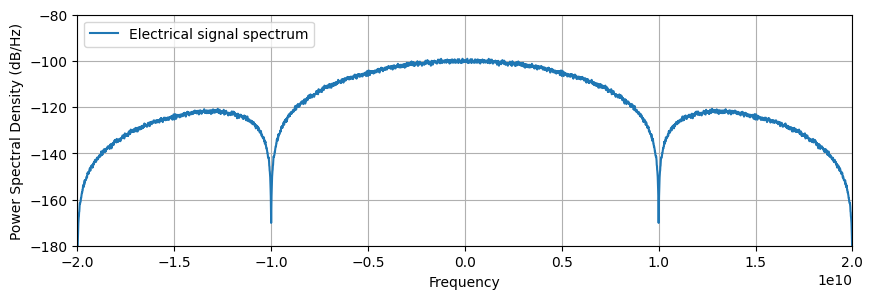

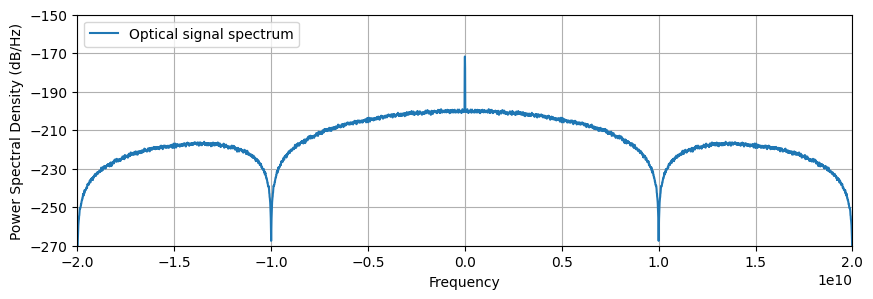

In [14]:
#1. Cấu hình Tham số Mô phỏng & Khai báo MZM
# simulation parameters
SpS = 16 # Số lượng mẫu mô phỏng cho 1 ký hiệu (Symbol)
Rs     = 10e9          # Symbol rate (for the case of OOK Rs = Rb): tốc dộ ký hiệu (Symbol rate) của tín hiệu OOK, trong trường hợp này Rs = Rb (bit rate). 10e9 = 10 Gbps
Ts     = 1/Rs          # Symbol period in seconds: Chu kỳ của 1 ký hiệu: Ts = 0.1 ns (100 ps)
Fa     = 1/(Ts/SpS)    # Signal sampling frequency (samples/second): Tần số lấy mẫu mô phỏng: Fa = 160 GHz
Ta     = 1/Fa          # Sampling period: Chu kỳ lấy mẫu: Ta = 6.25 ps

Pi_dBm = -17  # Công suất nguồn Laser đưa vào MZM tính theo dBm (-17 dBm)

# MZM parameters
Vπ = 2 # Điện áp chuyển pha 180 độ
Vb = -Vπ/2 # Điện áp phân cực Bias: Vb = -1V (Điểm Quadrature)
Pi = 10**(Pi_dBm/10)*1e-3 # Chuyển đổi công suất Laser sang Watt (Pi = 19.95 uW)

#2. Phát Dãy Bit Ngẫu nhiên & Định hình Xung Điện NRZ
# generates sequence of pseudo-random bits
bits   = np.random.randint(2, size=100000) # Tạo chuỗi 100,000 bit ngẫu nhiên (0 và 1)   
n      = np.arange(0, bits.size) # Tạo mảng chỉ số từ 0 đến độ dài của chuỗi bit

# maps bits to electrical pulses
symbTx = 2*bits-1 # maps bits to electrical pulses: ánh xạ bit 0 thành -1 và bit 1 thành +1 để tạo ra chuỗi tín hiệu điện tử symbTx(t) với các mức điện áp tương ứng.
symbTx = symbTx/np.sqrt(signalPower(symbTx)) #Chuẩn hóa công suất trung bình của tín hiệu điện về 1 W
# upsampling
symbolsUp = upsample(symbTx, SpS) #Chèn 15 số 0 vào giữa các mẫu để đạt SpS = 16

# typical NRZ pulse
paramPS = parameters()
paramPS.pulseType = 'nrz' # Chọn dạng xung chữ nhật NRZ
paramPS.SpS = SpS # Số lượng mẫu mô phỏng cho 1 ký hiệu
pulse = pulseShape(paramPS) # Tạo xung NRZ
pulse = pulse/max(abs(pulse)) # Chuẩn hóa biên độ xung NRZ về 1 (để đảm bảo công suất trung bình của xung là 1 W).

#3. Điều chế Quang MZM & Ước lượng PSD
# pulse formatting
sigTx  = firFilter(pulse, symbolsUp) # Lọc FIR để tạo dạng sóng điện NRZ sigTx(t) liên tục

# optical modulation
Ai     = np.sqrt(Pi) # Biên độ trường quang vào: Ai = sqrt(Pi)
paramMZM = parameters()
paramMZM.Vpi = Vπ # Điện áp chuyển pha 180 độ
paramMZM.Vb = Vb # Điện áp phân cực Bias: Vb = -1V (Điểm Quadrature)
sigTxo = mzm(Ai, sigTx, paramMZM) # Tín hiệu quang đầu ra của MZM sigTxo(t) = Ai*cos(pi*sigTx(t)/Vπ + pi*Vb/Vπ)

print('Average modulated optical signal power (mW): %.7f mW'%(signalPower(sigTxo)/1e-3)) # In ra công suất trung bình của tín hiệu quang điều chế
print('Average modulated optical signal power (dBm): %.7f dBm'%(10*np.log10(signalPower(sigTxo)/1e-3)))

# psd plot 1: Tín hiệu điện NRZ
plt.figure();
plt.xlim(-2*Rs,2*Rs);
plt.ylim(-180,-80);
plt.psd(sigTx,Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'Electrical signal spectrum')
plt.legend(loc='upper left');

# psd plot 2: Tín hiệu quang OOK sau MZM
plt.figure();
plt.xlim(-2*Rs,2*Rs);
plt.ylim(-270,-150);
plt.psd(np.abs(sigTxo)**2,Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'Optical signal spectrum')
plt.legend(loc='upper left');

### Simulating p-i-n receiver noise sources

Pin[Rx] = -20.02 dBm
SNR[theory] = 11.49 dB
SNR[yes] = 11.47 dB


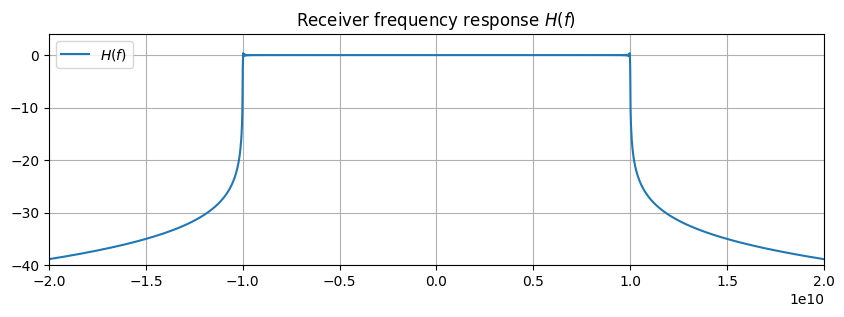

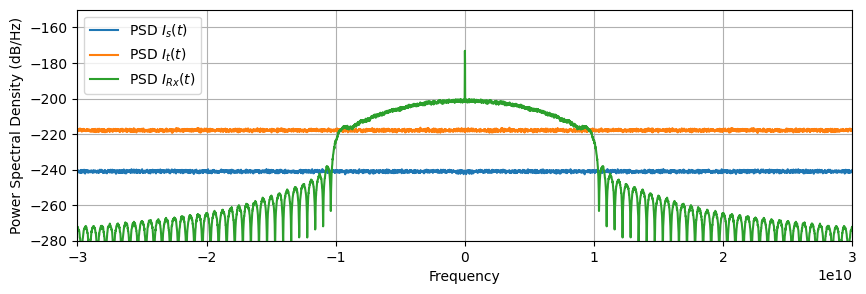

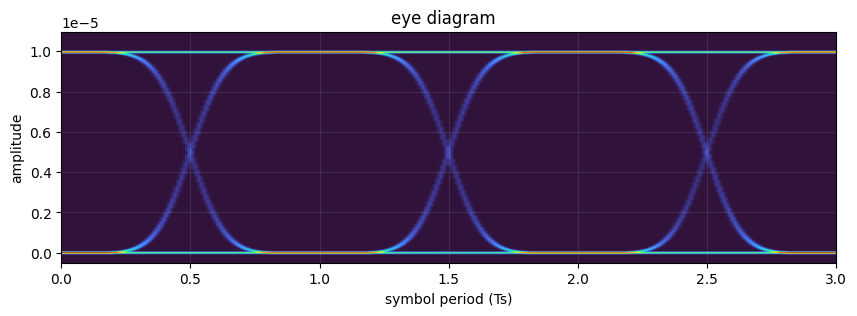

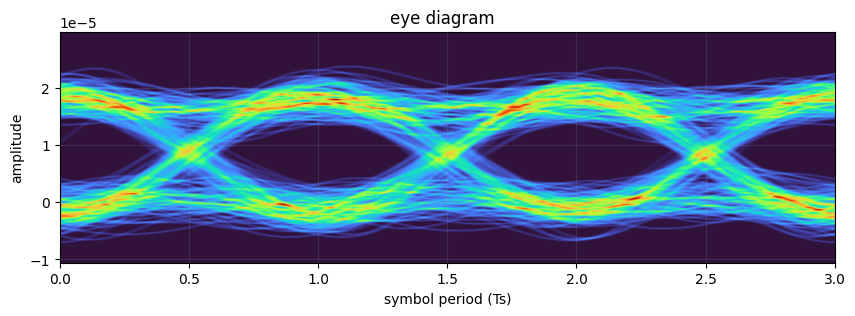

In [15]:
#1. Khai báo Tham số Bộ Thu & Tạo Nguồn Nhiễu
# receiver parameters
Tc = 25    # temperature in Celsius
B  = 10e9  # receiver band in Hz
R  = 0.85  # A/W responsiveness: Độ nhạy quang (Responsivity R) của Photodiode tức mỗi 1 cs quang tạo ra 0.85A dòng điện.
Id = 5e-9  # dark current in nA: Khai báo dòng điện tối trong photodiode
RL = 50    # RL to Ohms: Khai báo điện trở tải (load resistor) của bộ thu quang là 50 Ohms, đây là giá trị tiêu chuẩn trong các hệ thống truyền thông quang.
        
Pin = (np.abs(sigTxo)**2).mean() # Mean average optical power received 
   #Tính công suất quang trung bình thu được (Pin = 0.01 mW = -20 dBm) (LẤY TỪ CELL CODE TRÊN)

# noise free photocurrent
Ip = Rd*np.abs(sigTxo)**2 #Tính dòng quang điện trung bình (DÒNG LÝ TƯỞNG KHÔNG NHIỄU)

# shooting noise (NHIỄU HẠT)
σ2_s = 2*q*(Rd*Pin + Id)*B  # variance: Phương sai nhiễu hạt lý thuyết (σ_s^2)

# thermal noise (NHIỄU NHIỆT)
T = Tc + 273.15     # temperature in Kelvin: Chuyển đổi nhiệt độ từ độ C sang Kelvin bằng cách cộng thêm 273.15.
σ2_T = 4*kB*T*B/RL  # thermal noise variance: Phương sai nhiễu nhiệt lý thuyết (σ_T^2)

# adds p-i-n receiver noise to signals
Is = normal(0, np.sqrt(Fa*(σ2_s/(2*B))), Ip.size) #Tạo dòng nhiễu hạt Gaussian ngẫu nhiên trong miền thời gian Is(t)
It = normal(0, np.sqrt(Fa*(σ2_T/(2*B))), Ip.size) #Tạo dòng nhiễu nhiệt Gaussian ngẫu nhiên trong miền thời gian It(t)
   #Do tạo tín hiệu nhiễu ngẫu nhiên ở tần số lấy mẫu Fa = 160GHz (rộng hơn băng thông bộ thu B = 10GHz), phương sai nhiễu cần được nhân tỷ lệ để khi qua bộ lọc LPF, công suất nhiễu chuẩn hóa về đúng giá trị σ^2.

#2. Phát hiện Tín hiệu qua Photodiode & Bộ lọc LPF
# detects the signal with the pin photodiode (model implemented in OptiCommPy)
paramPD = parameters()
paramPD.R = R         # A/W responsiveness
paramPD.Tc = Tc       # temperature in Celsius
paramPD.Id = Id       # dark current in A
paramPD.RL = RL       # RL to Ohms
paramPD.B = B         # Hz bandwidth
paramPD.Fs = Fa 
paramPD.ideal = False
I_Rx = photodiode(sigTxo, paramPD) #Cho tín hiệu quang qua hàm Photodiode PIN thực tế (cộng cả nhiễu)

# Rx filtering
N = 8001 #Số bậc của bộ lọc FIR
h = lowPassFIR(B, Fa, N, typeF='rect') # Bộ lọc thông thấp FIR lý tưởng (chữ nhật) băng thông B = 10 GHz

freq = fftshift(fftfreq(h.size, d=1/Fa)) # Tính tần số cho biểu đồ tần số
plt.figure()
plt.plot(freq, 10*np.log10(np.abs(fftshift(fft(h)))),label='$H(f)$') # Vẽ đồ thị tần số của bộ lọc
plt.legend(loc='upper left'); # Hiển thị chú thích
plt.xlim(-2*Rs,2*Rs); # Giới hạn trục X từ -2*Rs đến +2*Rs để hiển thị đáp ứng tần số của bộ lọc trong khoảng tần số từ -20GHz đến +20GHz.
plt.ylim(-40,4); # Giới hạn trục Y từ -40 đến 4
plt.title('Receiver frequency response $H(f)$') # Hiển thị tiêu đề đồ thị (ĐÁP ỨNG TẦN SỐ CỦA BỘ LỌC THU)
plt.grid();

#3. Lọc Nhiễu, Ước lượng SNR & In Kết quả
# plot psds
plt.figure();
plt.xlim(-3*Rs,3*Rs); # Giới hạn trục X từ -3*Rs đến +3*Rs để hiển thị phổ nhiễu trong khoảng tần số từ -30GHz đến +30GHz.
plt.ylim(-280,-150);
plt.psd(Is, Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'PSD $I_s(t)$') #Phổ nhiễu hạt
plt.psd(It, Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'PSD $I_t(t)$') # Phổ nhiễu nhiệt
plt.psd(I_Rx, Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'PSD $I_{Rx}(t)$') #Phổ tín hiệu thu sau PIN
plt.legend(loc='upper left');

# calculating the in the SNR simulation 
Ip_Rx  = firFilter(h, Ip) # Tín hiệu điện lý tưởng qua LPF
Is_Rx  = firFilter(h, Is) # Dòng nhiễu hạt qua LPF
It_Rx  = firFilter(h, It) # Dòng nhiễu nhiệt qua LPF

# Theoretical SNR [Eq. (16)] Tính SNR Lý thuyết (dạng lần)
SNR_th  = (Ip**2).mean()/(σ2_s + σ2_T) 

# Numerically estimated SNR in simulation Tính SNR Mô phỏng thực tế
SNR_est = (Ip_Rx**2).mean()/(Is_Rx**2 + It_Rx**2).mean()

#CHUYỂN ĐỔI ĐƠN VỊ VÀ IN RA 
print('Pin[Rx] = %.2f dBm'%(10*np.log10(Pin/1e-3))) 
print('SNR[theory] = %.2f dB'%(10*np.log10(SNR_th)))
print('SNR[yes] = %.2f dB'%(10*np.log10(SNR_est)))

# eye diagram
Nsamples = 20000*SpS
eyediagram(Ip,  Ip.size-SpS, SpS, ptype='fancy')
eyediagram(I_Rx, I_Rx.size-SpS, SpS, ptype='fancy')

### APD-based receptors

The photocurrent generated by an avalanche photodiode (*avalanche photodiode* - APD) is given by

$$
\begin{equation}\label{eq20}
I_{p}=M R_{d} P_{i n}=R_{\mathrm{APD}} P_{\mathrm{in}}
\end{equation}
$$

where $R_{\mathrm{APD}} \equiv M R_{d}$ is the APD responsiveness and $M$ is the associated multiplicative factor.

#### Shooting noise

The shot noise power of an APD is given by
$$
\begin{equation}\label{eq21}
\sigma_{s}^{2}=2 q M^{2} F_{A}\left(R_{d} P_{\mathrm{in}}+I_{d}\right) \Delta f,
\end{equation}
$$

where $F_{A}$ is the excess noise factor, given by

$$
\begin{equation}\label{eq22}
F_{A}(M)=k_{A} M+\left(1-k_{A}\right)(2-1 / M).
\end{equation}
$$

$$
\begin{equation}\label{eq23}
\mathrm{SNR}=\frac{I_{p}^{2}}{\sigma_{s}^{2}+\sigma_{T}^{2}}=\frac{\left(M R_{d} P_{\text {in }}\right)^{2}}{2 q M^{2} F_{A}\left(R_{d} P_{\text {in }}+I_{d}\right) \Delta f+4\left(k_{B} T / R_{L}\right) F_{n} \Delta f}
\end{equation}
$$

## Receptor sensitivity

Once present in the system, noise imposes limitations on the performance of receivers and, consequently, on the transmission rates that can be achieved by the communication system.

One of the most important performance parameters in digital optical receivers is the bit-error rate (*bit-error rate* - BER), which indicates the frequency at which the decision-making circuit makes an error in identifying a bit transmitted from the received signal. For example, if the decision-making circuit makes on average one error for every million bits transmitted, we have $\mathrm{BER} = 1/10^6=1 \times 10^{-6}$. Standards adopted in optical communications systems engineering generally require BER values ​​$< 10^{-9}$, or $<10^{-12}$.

The BER of a given system, in turn, depends on the SNR values ​​of the signals detected at the receiver. As seen previously, the SNR directly depends on the optical signal power $P_{in}$ present at the receiver input. A common parameter associated with every optical receiver is *sensitivity*, which refers to the lowest value of received power necessary for the receiver to operate with a certain BER.

### AWGN Channel (*Additive White Gaussian Noise Channel*)

Assuming that the detected optical signal generates an electrical signal $y(t)$ that corresponds to the transmitted signal $x(t)$ added to the signal $n(t)$, resulting from the addition of the shot noise and the thermal noise at the *front-end* of the receiver, we have that

$$
\begin{align}
y(t) &= x(t) + n(t)\nonumber\\
     &= \sum_k s_kp(t-kT_s) + n(t).
\end{align}
$$

For simplicity and without loss of generality, we assume that the electrical signal $x(t)$ has zero mean.

### Filtering on the receiver

<img src="../figuras/MF.png" width="500">

Firstly, the received signal $y(t)$ must pass through an impulse response filter $h(t)$, whose function is to eliminate noise components outside the $x(t)$ band and deliver a signal $\hat{y}(t)$ with a maximum SNR to the decision-making circuit. Then,

$$
\begin{align}
\hat{y}(t) &= y(t) \ast h(t)\nonumber\\
           &= \left[\sum_k s_kp(t-kT_s)\right]\ast h(t) + n(t)\ast h(t)\nonumber\\
           &= \sum_k s_k\int_{-\infty}^{\infty}p(\tau-kT_s)h(t-\tau)d\tau + \int_{-\infty}^{\infty}n(t)h(t-\tau)d\tau\nonumber\\
           &= \hat{x}(t) + \hat{n}(t).
\end{align}
$$

Then, the signal $\hat{y}(t)$ will be sampled at moments $t=kT_s$, that is, in the middle of the signaling interval, where its SNR is maximum. For each signaling interval, the decision circuit will receive a sample $\hat{y}(kT_s)$ given by

$$
\begin{equation}
\hat{y}(kT_s) = \hat{x}(kT_s) + \hat{n}(kT_s).             
\end{equation}
$$

This way, we can now calculate the SNR of the signal $\hat{y}(kT_s)$ delivered to the decision circuit. For the signal strength, $P_s$, we have

$$
\begin{align}
P_s &= E[\hat{x}(kT_s)^2] \nonumber\\
    &= E\left[ \left(s_k\int_{-\infty}^{\infty}p(\tau-kT_s)h(kT_s-\tau)d\tau\right)^2 \right] \nonumber\\
    &= E\left[s_k^2\right] \left(\int_{-\infty}^{\infty}p(\tau-kT_s)h(kT_s-\tau)d\tau\right)^2.
\end{align}
$$

For the noise power, $P_n$, we have 

$$
\begin{align}
P_n &= E[\hat{n}(kT_s)^2] \nonumber\\
    &= E\left[\left(\int_{-\infty}^{\infty}n(\tau)h(kT_s-\tau)d\tau\int_{-\infty}^{\infty}n(u)h(kT_s-u)du\right) \right] \nonumber\\
    &= \int_{-\infty}^{\infty}\int_{-\infty}^{\infty}E\left[n(\tau)n(u)\right]h(kT_s-\tau)h(kT_s-u)d\tau du\nonumber\\
    &= \sigma_n^2 \int_{-\infty}^{\infty}\int_{-\infty}^{\infty}\delta(\tau-u)h(kT_s-\tau)h(kT_s-u)d\tau du\nonumber\\
    &= \sigma_n^2 \int_{-\infty}^{\infty}h^2(kT_s-\tau)d\tau.
\end{align}
$$

Then,

$$
\begin{align}
\mathrm{SNR} &= \frac{P_s}{P_n} = \frac{E[\hat{x}(kT_s)^2]}{E[\hat{n}(kT_s)^2]} \nonumber\\
             &= \frac{E\left[s_k^2\right] \left(\int_{-\infty}^{\infty}p(\tau-kT_s)h(kT_s-\tau)d\tau\right)^2}{\sigma_n^2 \int_{-\infty}^{\infty}h^2(kT_s-\tau)d\tau}
\end{align}
$$

### Married filter

You want to choose a filter whose impulse response $h(t)$ maximizes the SNR value at $t=kT_s$. To this end, observing the result of the Cauchy–Schwarz inequality, let $g_{1}(t)$ and $ g_{2}(t)$ be signs of finite energy, we have that

$$
\begin{equation}
\left[\int_{-\infty}^{\infty} g_{1}(t) g_{2}(t) d t\right]^{2} \leq \int_{-\infty}^{\infty} g_{1}^{2}(t) d t \int_{-\infty}^{\infty} g_{2}^{2}(t) d t
\end{equation}
$$
with equality if, and only if, $g_{1}(t) = C g_{2}(t)$ for any arbitrary constant $C$. We then have

$$
\begin{equation}
\frac{\left[\int_{-\infty}^{\infty} g_{1}(t) g_{2}(t) d t\right]^{2}}{\int_{-\infty}^{\infty} g_{2}^{2}(t) d t} \leq \int_{-\infty}^{\infty} g_{1}^{2}(t) d t
\end{equation}
$$

Let $g_{1}(\tau)=p(\tau-kT_s)$ and $g_{2}(\tau)=h(kT_s-\tau)$, we can write

$$
\begin{equation}
\frac{\left[\int_{-\infty}^{\infty} p(\tau-kT_s) h(kT_s-\tau) d \tau\right]^{2}}{\int_{-\infty}^{\infty} h^2(kT_s-\tau) d \tau} \leq \int_{-\infty}^{\infty} p^2(\tau-kT_s) d \tau
\end{equation}
$$

Therefore, the maximum value that the SNR can achieve is limited to

$$
\begin{align}
\mathrm{SNR} &= \frac{E\left[s_k^2\right] \left(\int_{-\infty}^{\infty}p(\tau-kT_s)h(kT_s-\tau)d\tau\right)^2}{\sigma_n^2 \int_{-\infty}^{-\infty}h^2(kT_s-\tau)d\tau}\nonumber\\
             &\leq \frac{E\left[s_k^2\right]}{\sigma_n^2} \int_{-\infty}^{\infty} p^2(\tau-kT_s) d \tau
\end{align}
$$

Furthermore, the Cauchy–Schwarz theorem tells us that to achieve maximum SNR we can do $h(t)=p(-t)$. In this case, it is said that $h(t)$ is the "matched filter" to the pulse $p(t)$. Therefore, by filtering the received signal with a filter matched to the receiver, it is guaranteed that the SNR delivered to the decision-making circuit is the maximum possible and equal to

$$
\begin{align}
\mathrm{SNR} = \frac{E\left[s_k^2\right]}{\sigma_n^2} \int_{-\infty}^{\infty} p^2(\tau-kT_s) d \tau
\end{align}
$$

### Optimal decision maker: evaluating probabilities

The decision maker's role is to provide an estimate $\hat{b}_k$ of the *k*-th bit transmitted from $\hat{y}_k$. Several decision rules can be defined.

The optimal decision maker uses a decision rule that maximizes the probability of success *a posteriori* or, equivalently, that minimizes the probability of error *a posteriori*. To obtain optimal decision makers, it is necessary to probabilistically characterize the communications channel.

#### Metric of *posterior probabilities* (MP)

According to Bayes' theorem, a metric proportional to the *a posteriori* probability $P(b_k|\hat{y}_k)$ is given by

$$
\begin{equation}
\mathrm{MP}(b_k|\hat{y}_k) = p(\hat{y}_k|b_k)P(b_k)
\end{equation}
$$

where $P(b_k)$ is the *a priori* probability associated with bit $b_k$ and $p(\hat{y}_k|b_k)$ is the conditional distribution or *likelihood function* associated with the communications channel.

Decision rule: if $\mathrm{MP}(b_k=1|\hat{y}_k) > \mathrm{MP}(b_k=0|\hat{y}_k)$, then $\hat{b}_k=1$; if $\mathrm{MP}(b_k=0|\hat{y}_k) > \mathrm{MP}(b_k=1|\hat{y}_k)$, then $\hat{b}_k=0$.

We know that:

$$ p(\hat{y}_k|b_k=0) = \frac{1}{\sigma_{0} \sqrt{2 \pi}} e^{-\frac{\left(\hat{y}_k-I_0\right)^{2}}{2 \sigma_0^{2}}}$$

$$ p(\hat{y}_k|b_k=1) = \frac{1}{\sigma_{1} \sqrt{2 \pi}} e^{-\frac{\left(\hat{y}_k-I_1\right)^{2}}{2 \sigma_1^{2}}}$$

Therefore, we can define the ratio $\Lambda$ between MPs

$$
\begin{align}
\Lambda &= \frac{\mathrm{MP}(b_k=1, \hat{y}_k)}{\mathrm{MP}(b_k=0, \hat{y}_k)} 
         = \frac{p(\hat{y}_k|b_k=1)P(b_k=1)}{p(\hat{y}_k|b_k=0)P(b_k=0)}\\
        &= \frac{\sigma_0}{\sigma_1} \frac{P_1}{P_0} \left[\frac{e^{-\frac{\left(\hat{y}_k-I_1\right)^{2}}{2 \sigma_1^{2}}}}{e^{-\frac{\left(\hat{y}_k-I_0\right)^2}{2 \sigma_0^{2}}}}\right].        
\end{align}
$$

Note that $\Lambda\geq 0$. In function of $\Lambda$, the decision rule becomes: if $\Lambda>1$, $\hat{b}_k=1$; if $\Lambda<1$, $\hat{b}_k=0$.

Applying the logarithm 
$$
\begin{align}
\ln \Lambda &= \ln{\frac{\sigma_0}{\sigma_1} \frac{P_1}{P_0} \left[\frac{e^{-\frac{\left(\hat{y}_k-I_1\right)^{2}}{2 \sigma_1^{2}}}}{e^{-\frac{\left(\hat{y}_k-I_0\right)^2}{2 \sigma_0^{2}}}}\right]}\\ 
            &=\ln\left[\frac{\sigma_0}{\sigma_1}\right] + \ln\left[\frac{P_1}{P_0}\right] + \ln{\left[\frac{e^{-\frac{\left(\hat{y}_k-I_1\right)^{2}}{2 \sigma_1^{2}}}}{e^{-\frac{\left(\hat{y}_k-I_0\right)^2}{2 \sigma_0^{2}}}}\right]}\\
            &=\ln\left[\frac{\sigma_0}{\sigma_1}\right] + \ln\left[\frac{P_1}{P_0}\right] -\frac{\left(\hat{y}_k-I_1\right)^{2}}{2 \sigma_1^{2}} +\frac{\left(\hat{y}_k-I_0\right)^2}{2 \sigma_0^{2}}
\end{align}
$$

Depending on $\ln \Lambda$, the decision rule becomes: if $\ln\Lambda>0$, $\hat{b}_k=1$; if $\ln \Lambda<0$, $\hat{b}_k=0$.

Assuming that the bits are equiprobable, we have that $\frac{P_1}{P_0}=1$, that is, $\ln\left[\frac{P_1}{P_0}\right]= 0$ and also that, in practice, $\ln\left[\frac{\sigma_0}{\sigma_1}\right]\approx 0$.

$$
\begin{equation}
\ln \Lambda = -\frac{\left(\hat{y}_k-I_1\right)^{2}}{2 \sigma_1^{2}} +\frac{\left(\hat{y}_k-I_0\right)^2}{2 \sigma_0^{2}}
\end{equation}
$$

#### Optimal decision threshold $I_d$

At the optimal decision threshold $I_d$, we have $\ln \Lambda = 0$, i.e.

$$
\begin{equation}
\frac{\left(I_d-I_1\right)^{2}}{2 \sigma_1^{2}} = \frac{\left(I_d-I_0\right)^2}{2 \sigma_0^{2}}
\end{equation}
$$

$$
\begin{equation}
\frac{|I_d-I_1|}{\sigma_1} = \frac{|I_d-I_0|}{\sigma_0}
\end{equation}
$$

Since $I_0\leq I_d \leq I_1$, we have that $|I_d-I_1|=I_1-I_d$ and $|I_d-I_0|=I_d-I_0$, and then

$$
\begin{equation}
\frac{I_1-I_d}{\sigma_1} = \frac{I_d-I_0}{\sigma_0}.
\end{equation}
$$

Finally, 

$$
\begin{equation}
I_d = \frac{\sigma_0I_1 + \sigma_1I_0}{\sigma_0 + \sigma_1}.
\end{equation}
$$

Depending on the optimal decision threshold $I_d$, the optimal decision rule becomes: if $\hat{y}_k>I_d$, $\hat{b}_k=1$; if $\hat{y}_k<I_d$, $\hat{b}_k=0$.

### Bit error probability $P_b$

The bit error probability is defined as the probability that the bit $\hat{b}_k$ estimated by the decision maker is different from the transmitted $b_k$.

$$
\begin{align}
P_b &= P(\hat{b}_k=0, b_k=1) + P(\hat{b}_k=1, b_k=0) \nonumber\\
    &= P(\hat{b}_k=0 | b_k=1)P(b_k=1) + P(\hat{b}_k=1 | b_k=0)P(b_k=0) \nonumber\\
    &= P(\hat{y}_k < I_d | b_k=1)P(b_k=1) + P(\hat{y}_k > I_d | b_k=0)P(b_k=0)
\end{align}
$$

$$
\begin{align}
&P(\hat{y}_k < I_d | b_k=1)&=\frac{1}{\sigma_{1} \sqrt{2 \pi}} \int_{-\infty}^{I_d} \exp \left(-\frac{\left(\hat{y}_k-I_{1}\right)^{2}}{2 \sigma_{1}^{2}}\right) d\hat{y}_k=\frac{1}{2} \operatorname{erfc}\left(\frac{I_{1}-I_d}{\sigma_{1} \sqrt{2}}\right) \\
&P(\hat{y}_k > I_d| b_k=0)&=\frac{1}{\sigma_{0} \sqrt{2 \pi}} \int_{I_d}^{\infty} \exp \left(-\frac{\left(\hat{y}_k-I_{0}\right)^{2}}{2 \sigma_{0}^{2}}\right) d \hat{y}_k=\frac{1}{2} \operatorname{erfc}\left(\frac{I_d-I_{0}}{\sigma_{0} \sqrt{2}}\right)
\end{align}
$$

where $\operatorname{erfc}(x)$ is the complementary error function, defined by

$$
\begin{equation}
\operatorname{erfc}(x)=\frac{2}{\sqrt{\pi}} \int_{x}^{\infty} \exp \left(-\gamma^{2}\right) d \gamma.
\end{equation}
$$

Let $P(b_k=0) = P(b_k=1) = 0.5$, we have

$$
\begin{equation}
P_b=\frac{1}{4}\left[\operatorname{erfc}\left(\frac{I_{1}-I_{D}}{\sigma_{1} \sqrt{2}}\right)+\operatorname{erfc}\left(\frac{I_{D}-I_{0}}{\sigma_{0} \sqrt{2}}\right)\right]
\end{equation}
$$

We found a more convenient expression for $P_b$ in function of the parameter $Q$, defined by

$$
\begin{equation}
Q \equiv \frac{I_1-I_d}{\sigma_1} = \frac{I_d-I_0}{\sigma_0}.
\end{equation}
$$

Replacing $I_d = (\sigma_0I_1 + \sigma_1I_0)/(\sigma_0 + \sigma_1)$, we have 

$$
\begin{equation}
Q \equiv \frac{I_1-I_0}{\sigma_0 + \sigma_1},
\end{equation}
$$

and 

$$
\begin{equation}
P_b=\frac{1}{2} \operatorname{erfc}\left(\frac{Q}{\sqrt{2}}\right) \approx \frac{\exp \left(-Q^{2} / 2\right)}{Q \sqrt{2 \pi}}
\end{equation}
$$

In [16]:
from scipy.special import erfc
#Nạp hàm bù lỗi erfc(x) – công cụ toán học tính toán diện tích phần đuôi của phân bố Gauss.

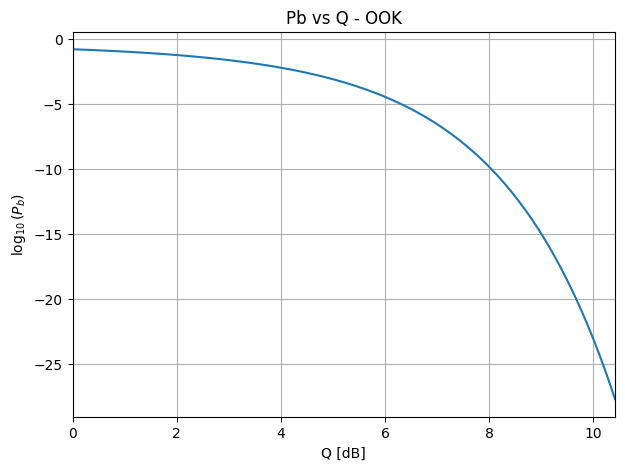

In [17]:
#Khởi tạo mảng giá trị tham số Q (từ 1 đến 11, bước nhảy 0.1)
Q  = np.arange(1, 11.1, 0.1)

QdB = 10*np.log10(Q) # Chuyển đổi mảng Q sang đơn vị logarithmic dB

Pb = 0.5*erfc(Q/np.sqrt(2)) # Tính toán xác suất lỗi bit Pb (BER) theo công thức lý thuyết OOK

#Vẽ đồ thị biểu diễn mối liên hệ giữa log10(Pb) và Q (dB)
plt.figure(figsize=(7,5))
plt.plot(QdB, np.log10(Pb),label='Pb')
plt.title('Pb vs Q - OOK')
plt.xlabel('Q [dB]')
plt.ylabel('$\\log_{10}(P_b)$');
plt.xlim(min(QdB),max(QdB))
plt.grid()

#### Example: 10G OOK simulation

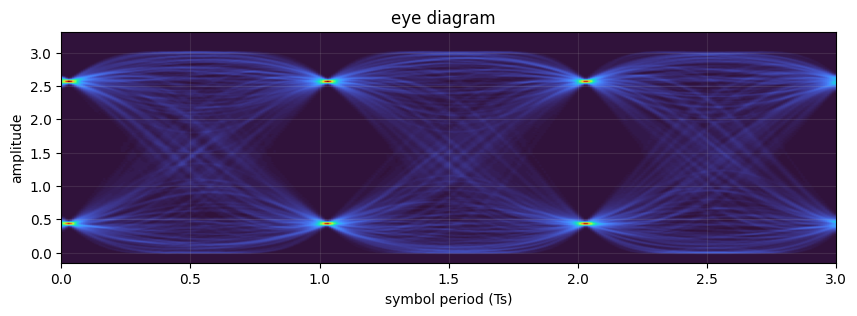

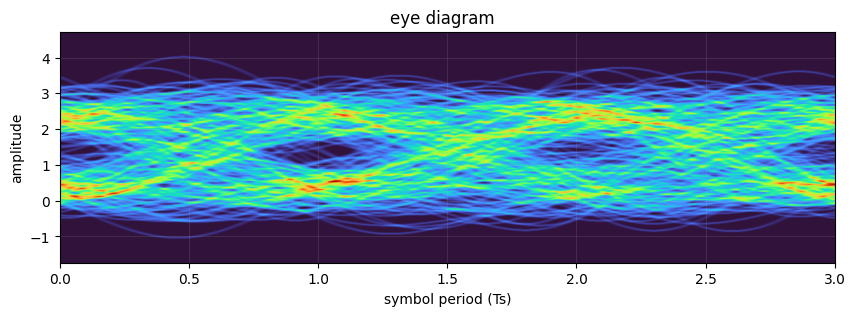

Pin[Rx] = -21.00 dBm
SNR[yes] = 10.30 dB 

Eye diagram parameters:
I0 = 0.40
I1 = 2.36
σ0 = 0.38
σ1 = 0.38
Optimal threshold Id = 1.38
Q = 2.57 

Total errors counted = 490
BER = 4.91e-03
Pb = 5.06e-03


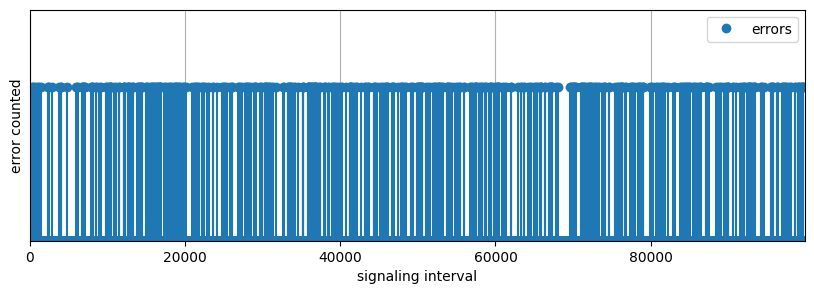

In [18]:
# simulation parameters
SpS    = 16         # number of samples per symbol
Rs     = 10e9       # Symbol rate (for the case of OOK Rs = Rb)
Ts     = 1/Rs       # Symbol period in seconds
Fa     = 1/(Ts/SpS) # Signal sampling frequency (samples/second)
Ta     = 1/Fa       # Sampling period

Pi_dBm = -18  # optical signal power at modulator input in dBm

# MZM parameters
Vπ = 2
Vb = -Vπ/2
Pi = 10**(Pi_dBm/10)*1e-3 # optical signal power in W at the MZM input

# receiver parameters
Tc  = 25    # temperature in Celsius
Rd  = 0.85  # A/W responsiveness
Id  = 5e-9  # dark current in nA
RL  = 50    # RL to Ohms
B   = 10e9   # receiver band in Hz

# ############ Simulation #############

# ## Transmitter

# generates sequence of pseudo-random bits
bitsTx   = np.random.randint(2, size=100000)    
n        = np.arange(0, bitsTx.size)

# maps bits to electrical pulses
symbTx = 2*bitsTx-1
symbTx = symbTx/np.sqrt(signalPower(symbTx))

# upsampling
symbolsUp = upsample(symbTx, SpS)

# pulse
paramPS = parameters()
paramPS.pulseType = 'nrz'
paramPS.SpS = SpS
pulse = pulseShape(paramPS)
paramPS = parameters()
paramPS.pulseType = 'rrc'
paramPS.SpS = SpS
paramPS.nFilterTaps = 2048
paramPS.rollOff = 0.001
pulse = pulseShape(paramPS)
pulse = pulse/max(abs(pulse))

# pulse formatting
sigTx  = firFilter(pulse, symbolsUp)

# optical modulation
Ai     = np.sqrt(Pi)
paramMZM = parameters()
paramMZM.Vpi = Vπ
paramMZM.Vb = Vb
sigTxo = mzm(Ai, 0.5*sigTx, paramMZM)

# ## Receiver
Pin = (np.abs(sigTxo)**2).mean() # Mean average optical power received

# detects the signal with the pin photodiode (model implemented in OptiCommPy)
paramPD = parameters()
paramPD.R = Rd         # A/W responsiveness
paramPD.Tc = Tc       # temperature in Celsius
paramPD.Id = Id       # dark current in A
paramPD.RL = RL       # RL to Ohms
paramPD.B = B         # Hz bandwidth
paramPD.Fs = Fa 
paramPD.ideal = False

I_Rx = photodiode(sigTxo, paramPD)
I_Rx = I_Rx/np.std(I_Rx)

# ########### calculating the SNR in the simulation

# shooting noise
σ2_s = 2*q*(Rd*Pin + Id)*B  # variance

# thermal noise
T = Tc + 273.15     # temperature in Kelvin
σ2_T = 4*kB*T*B/RL  # thermal noise variance

# noise free photocurrent
Ip = Rd*np.abs(sigTxo)**2

# p-i-n receiver noise to signals
Is   = normal(0, np.sqrt(Fa*(σ2_s/(2*B))), Ip.size)
It   = normal(0, np.sqrt(Fa*(σ2_T/(2*B))), Ip.size)  

# Rx filtering
N = 8001
h = lowPassFIR(B, Fa, N, typeF='rect')
paramPS = parameters()
paramPS.pulseType = 'nrz'
paramPS.SpS = SpS
h = pulseShape(paramPS)

Ip_Rx  = firFilter(h, Ip)
Is_Rx  = firFilter(h, Is)
It_Rx  = firFilter(h, It)

# Numerically estimated SNR in simulation
SNR_est = np.var(Ip_Rx)/(np.var(Is_Rx) + np.var(It_Rx))

# #############################################

# generates signal for viewing the eye diagram
I_eye = I_Rx[100*SpS:I_Rx.size-100*SpS]

eyediagram(Ip/np.std(Ip),  Ip.size-SpS, SpS, ptype='fancy')
eyediagram(I_eye/np.std(I_eye), I_eye.size-SpS, SpS, ptype='fancy')

print('Pin[Rx] = %.2f dBm'%(10*np.log10(Pin/1e-3)))
print('SNR[yes] = %.2f dB \n'%(10*np.log10(SNR_est)))

# captures samples in the middle of signaling intervals
I_Rx  = I_Rx[0::SpS]

# obtains statistics of the received signal

I1 = np.mean(I_Rx[bitsTx==1]) # average value of I1
I0 = np.mean(I_Rx[bitsTx==0]) # average value of I0

σ1 = np.std(I_Rx[bitsTx==1]) # standard deviation σ1 of I1
σ0 = np.std(I_Rx[bitsTx==0]) # standard deviation σ0 of I0

Id = (σ1*I0 + σ0*I1)/(σ1 + σ0) # optimal decision threshold
Q  = (I1-I0)/(σ1 + σ0)         # Q factor

print('Eye diagram parameters:')
print('I0 = %.2f'%(I0))
print('I1 = %.2f'%(I1))
print('σ0 = %.2f'%(σ0))
print('σ1 = %.2f'%(σ1))
print('Optimal threshold Id = %.2f'%(Id))
print('Q = %.2f \n'%(Q))

# Apply the optimal decision rule
bitsRx = np.empty(bitsTx.size)
bitsRx[I_Rx>  Id] = 1
bitsRx[I_Rx<= Id] = 0

discard = 100
err = np.logical_xor(bitsRx[discard:bitsRx.size-discard], bitsTx[discard:bitsTx.size-discard])
BER = np.mean(err)

Pb = 0.5*erfc(Q/np.sqrt(2)) # theoretical error probability
print('Total errors counted = %d'%(err.sum()))
print('BER = %.2e'%(BER))
print('Pb = %.2e'%(Pb))


plt.plot(err,'o', label = 'errors')
plt.vlines(np.where(err>0), 0, 1)
plt.xlabel('signaling interval')
plt.ylabel('error counted')
plt.legend()
plt.grid()
plt.ylim(0, 1.5)
plt.xlim(0,err.size);
plt.yticks([]);  # Disable yticks.

In [19]:
from utils import genSignalGIF

In [20]:
from IPython.display import Image

I_Rx = photodiode(sigTxo, paramPD)
I_Rx = I_Rx/np.std(I_Rx)
#Nhận tín hiệu quang từ MZM qua mô hình PIN Photodiode (có tính đầy đủ nhiễu nhiệt và nhiễu hạt), sau đó chuẩn hóa theo độ lệch chuẩn std(I_Rx)

t = np.arange(len(Ip_Rx[0:2048]))
#t: Trục thời gian (tính theo mẫu) cho 2048 mẫu đầu tiên . 2048/16=128 bits

figName1  = '../figuras/sig.gif' 
figName2  = '../figuras/sigNoisy.gif'

windowSize = 256
# Khung cửa sổ hiển thị 256 mẫu tương ứng với 16 bits trượt dần qua thời gian trên đồ thị.

genSignalGIF(t, Ip_Rx[0:2048], windowSize, figName1, fram=128, inter=80)
genSignalGIF(t, I_Rx[0:2048], windowSize, figName2, fram=128, inter=80)
#Tạo 128 khung hình chuyển động (frames)
#Khoảng thời gian giữa mỗi khung hình là 80ms.


MovieWriter imagemagick unavailable; using Pillow instead.
MovieWriter imagemagick unavailable; using Pillow instead.


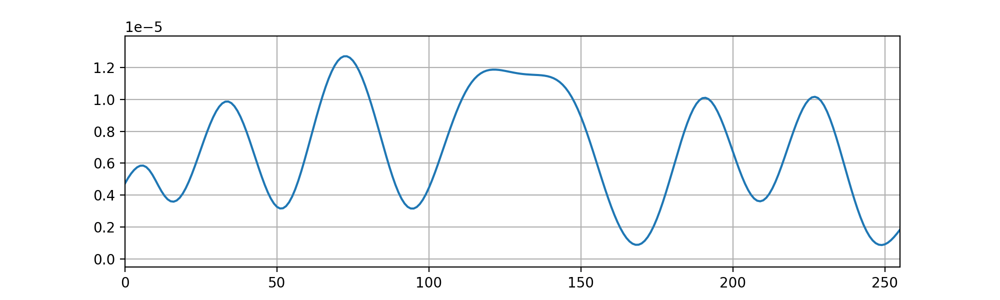

In [21]:
Image('../figuras/sig.gif', width=500)

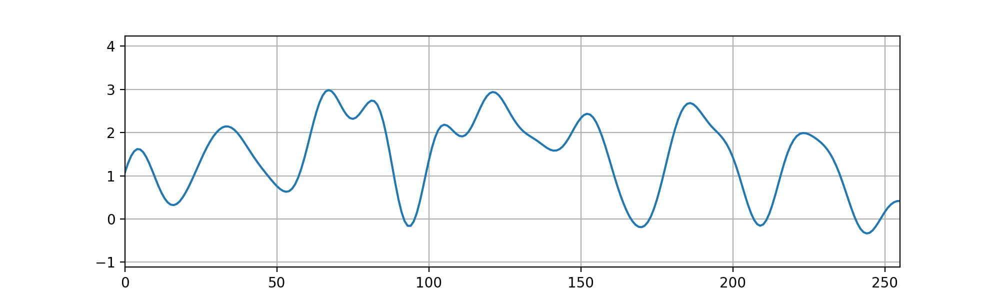

In [22]:
Image('../figuras/sigNoisy.gif', width=500)